Dataset chargé avec succès
  Marital status                  Application mode  Application order  \
0         single    2nd phase - general contingent                  5   
1         single  International student (bachelor)                  1   
2         single    1st phase - general contingent                  5   
3         single    2nd phase - general contingent                  2   
4        married                 Over 23 years old                  1   

                                Course Daytime/evening attendance  \
0      Animation and Multimedia Design                    Daytime   
1                              Tourism                    Daytime   
2                 Communication Design                    Daytime   
3         Journalism and Communication                    Daytime   
4  Social Service (evening attendance)               Evening time   

  Previous qualification  Previous qualification (grade) Nacionality  \
0    Secondary education                       

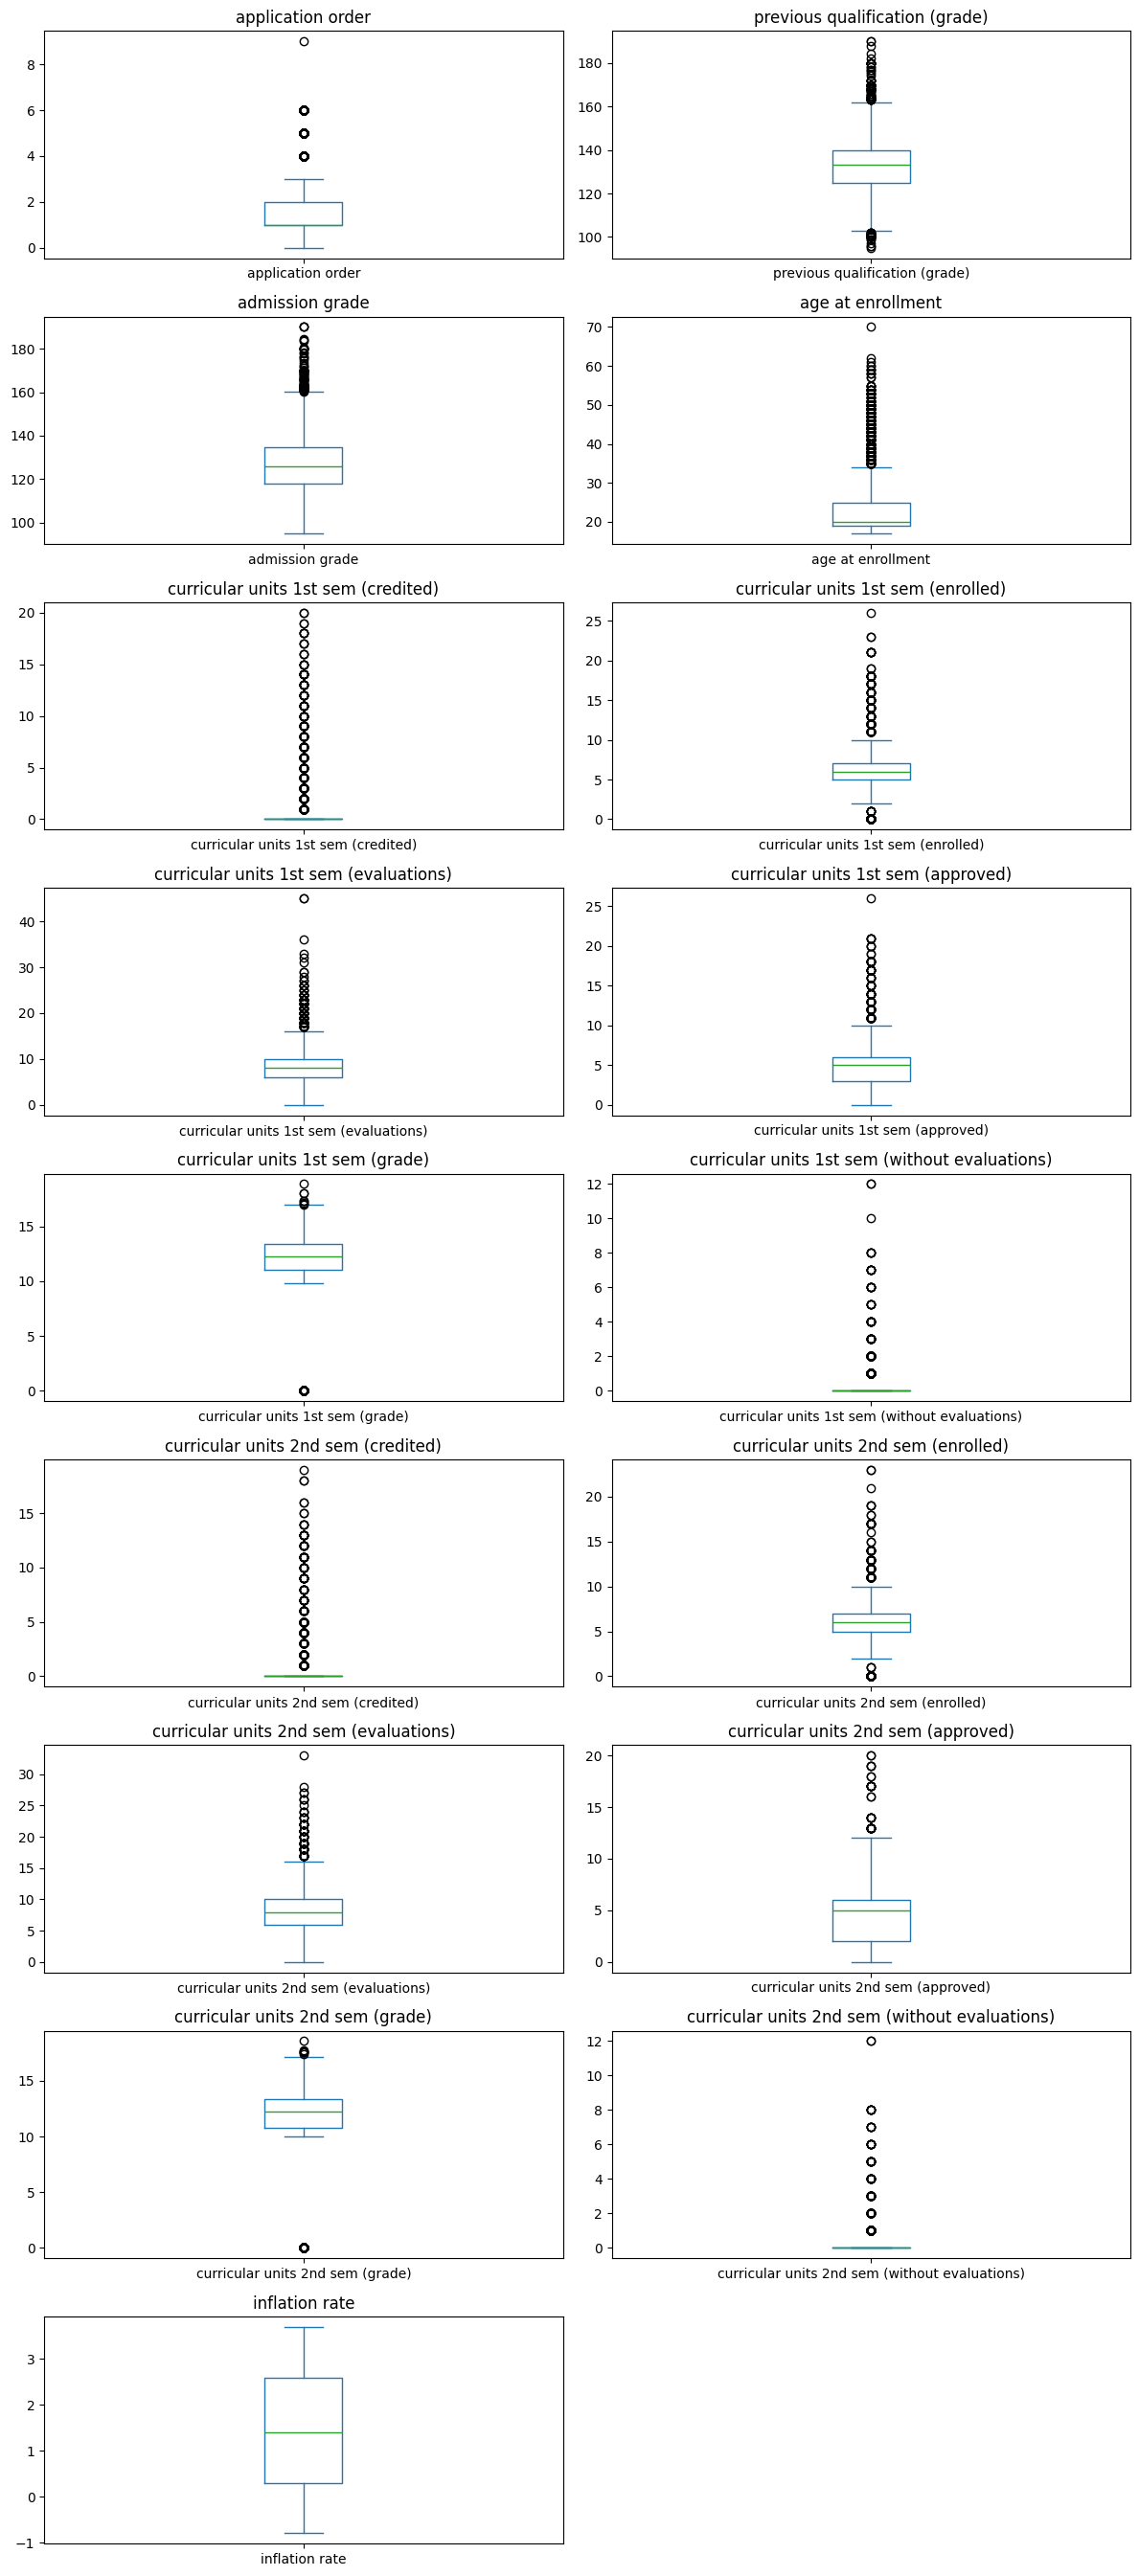

  marital status                  application mode  application order  \
0         single    2nd phase - general contingent                3.5   
1         single  International student (bachelor)                1.0   
2         single    1st phase - general contingent                3.5   
3         single    2nd phase - general contingent                2.0   
4        married                 Over 23 years old                1.0   

                                course daytime/evening attendance  \
0      Animation and Multimedia Design                    Daytime   
1                              Tourism                    Daytime   
2                 Communication Design                    Daytime   
3         Journalism and Communication                    Daytime   
4  Social Service (evening attendance)               Evening time   

  previous qualification  previous qualification (grade)  \
0    Secondary education                           122.0   
1    Secondary education  

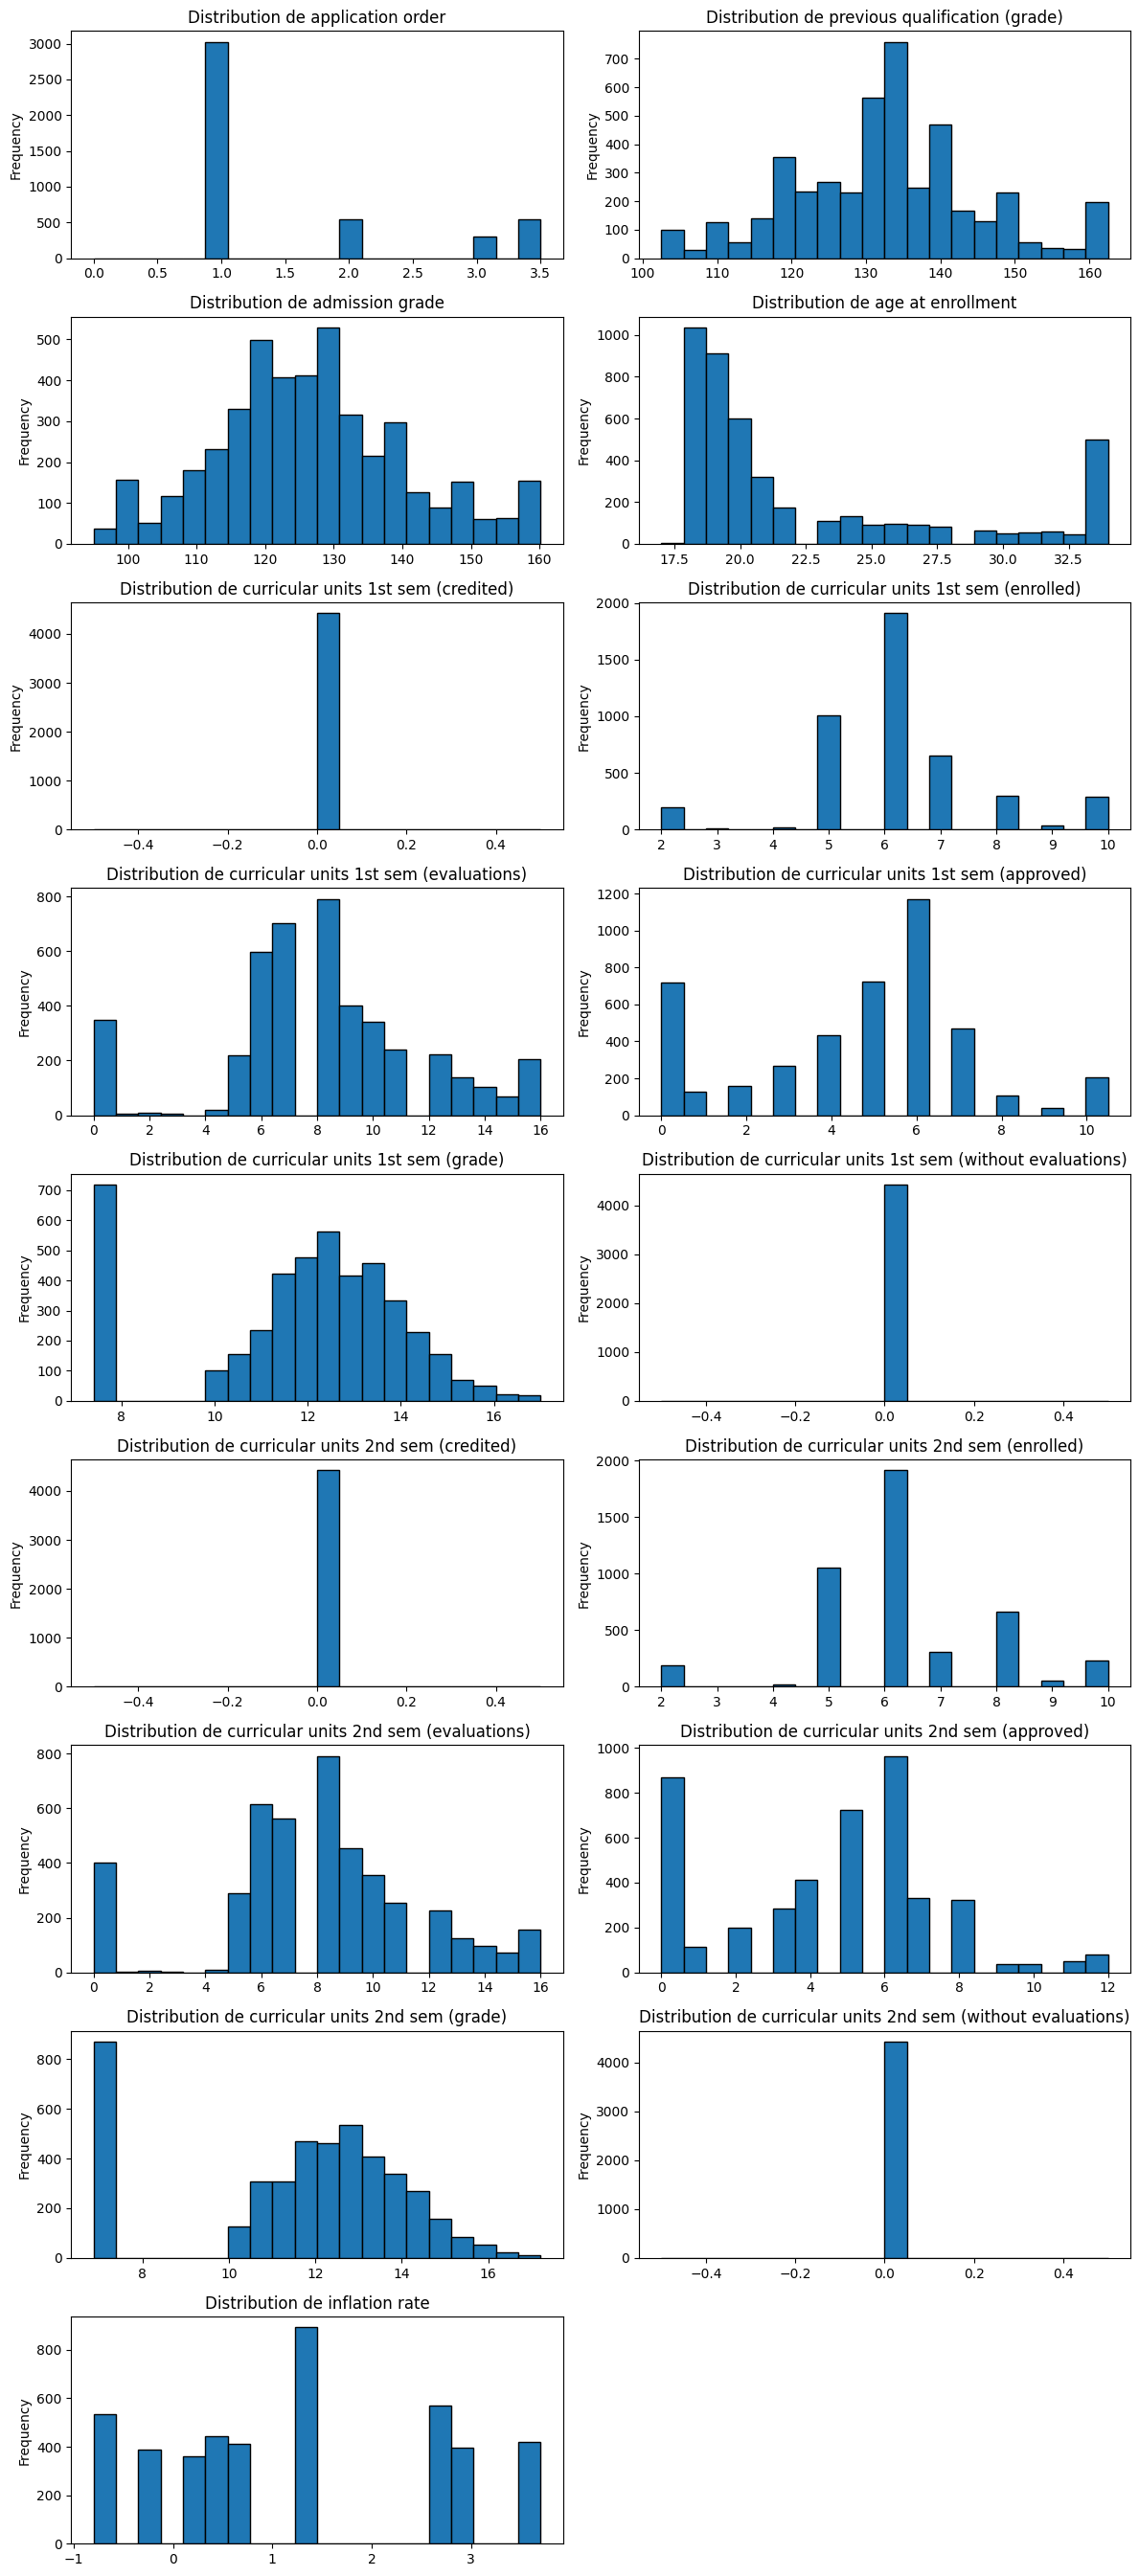

C:\Users\hp\AppData\Local\Temp\ipykernel_2756\3814771785.py:191: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col = df.select_dtypes(include='object').columns


marital status
marital status
single               3919
married               379
divorced               91
facto union            25
legally separated       6
widower                 4
Name: count, dtype: int64
application mode
application mode
1st phase - general contingent                         1708
2nd phase - general contingent                          872
Over 23 years old                                       785
Change of course                                        312
Technological specialization diploma holders            213
Holders of other higher courses                         139
3rd phase - general contingent                          124
Transfer                                                 77
Change of institution/course                             59
1st phase - special contingent (Madeira Island)          38
Short cycle diploma holders                              35
International student (bachelor)                         30
1st phase - special contingent (Az

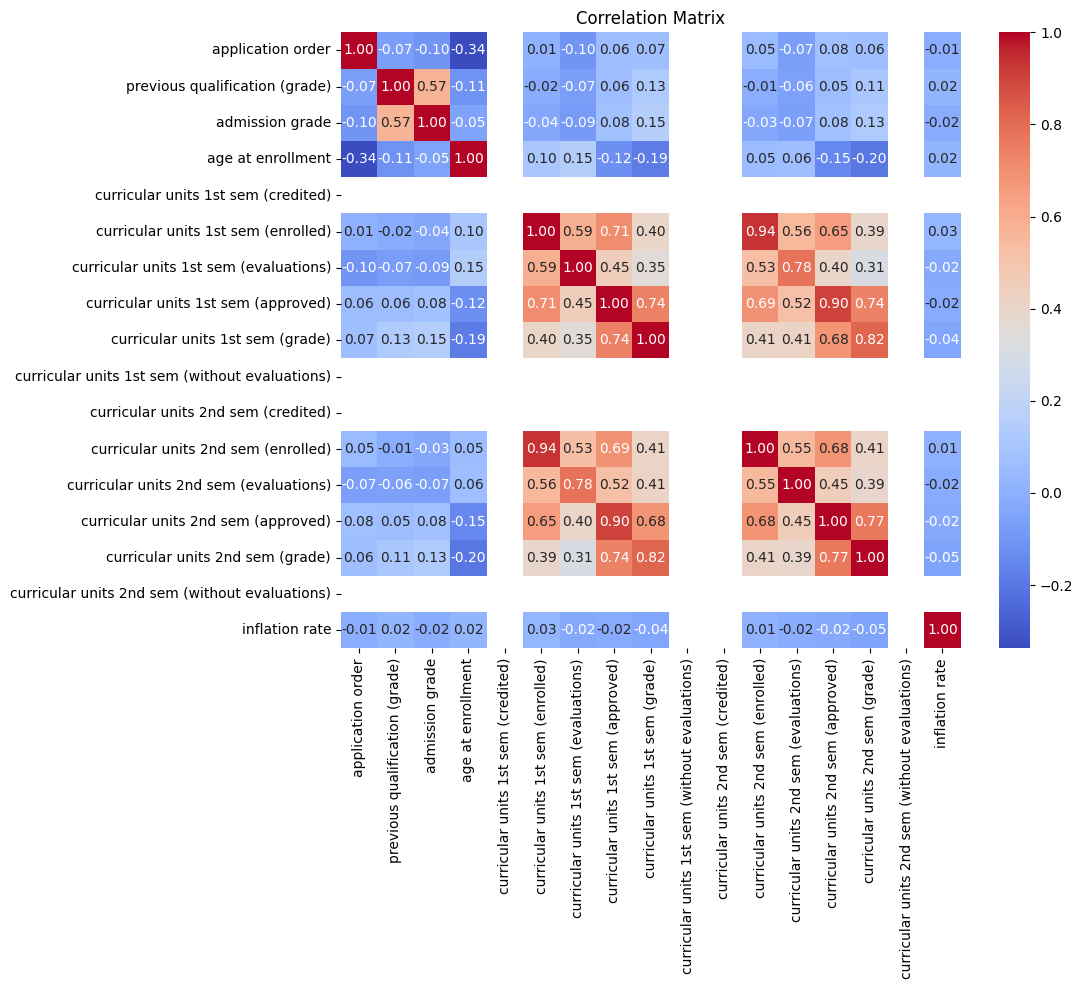

                                                Skewness  Kurtosis
application order                               1.249686 -0.091131
previous qualification (grade)                  0.128940  0.146472
admission grade                                 0.308995 -0.076047
age at enrollment                               1.198485 -0.033155
curricular units 1st sem (credited)             0.000000  0.000000
curricular units 1st sem (enrolled)             0.210775  1.783820
curricular units 1st sem (evaluations)         -0.124708  0.496285
curricular units 1st sem (approved)            -0.223636 -0.384931
curricular units 1st sem (grade)               -0.742649 -0.165532
curricular units 1st sem (without evaluations)  0.000000  0.000000
curricular units 2nd sem (credited)             0.000000  0.000000
curricular units 2nd sem (enrolled)             0.117190  1.301058
curricular units 2nd sem (evaluations)         -0.220269  0.450294
curricular units 2nd sem (approved)             0.002377 -0.40

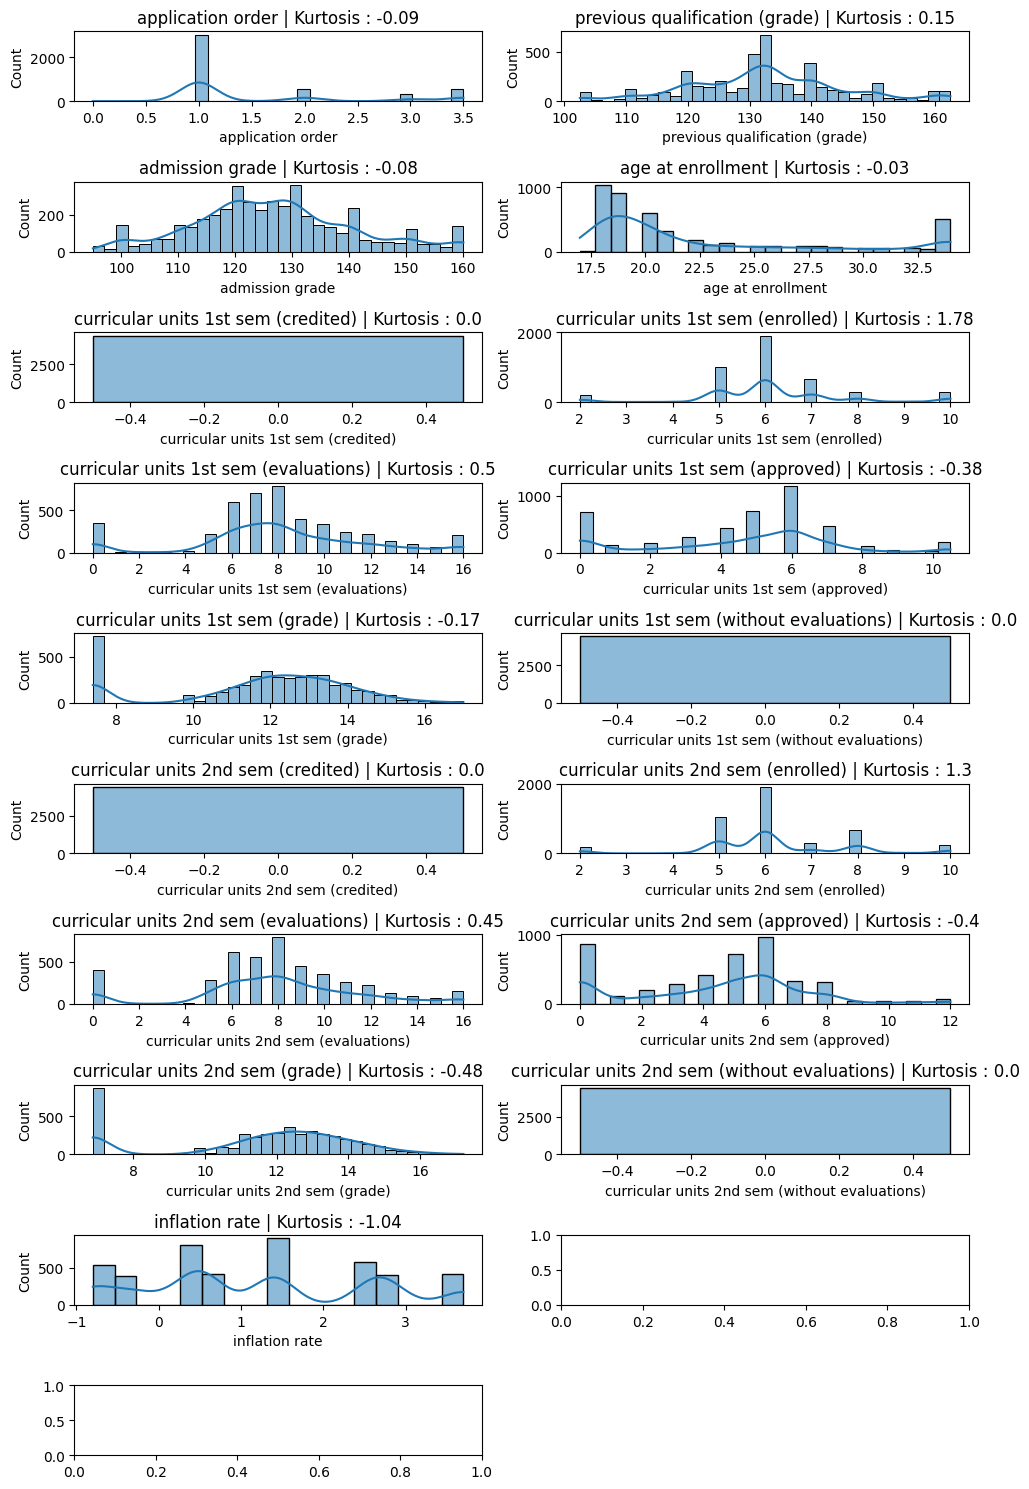

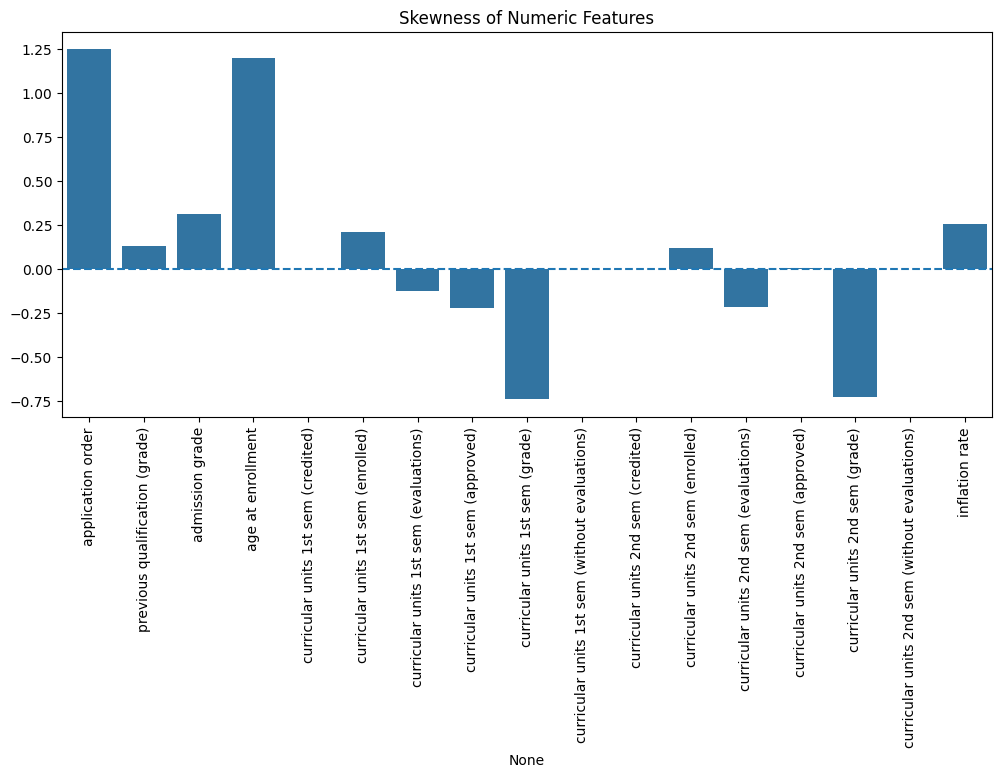

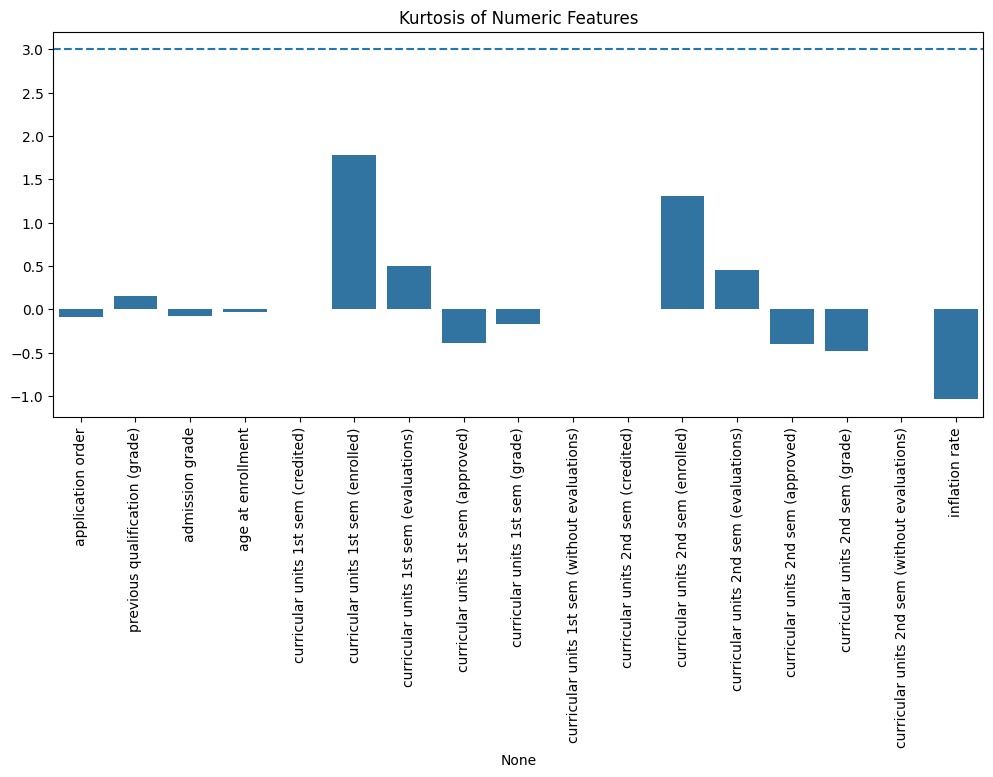

C:\Users\hp\AppData\Local\Temp\ipykernel_2756\3814771785.py:285: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


Target : target
(3539, 32)
(885, 32)
Normalisation terminée
target
0    1791
1    1791
2    1791
Name: count, dtype: int64
Accuracy: 0.7446327683615819
Precision: 0.7679927448805516
Recall: 0.7446327683615819
[[227  58  31]
 [ 24  87  40]
 [ 17  56 345]]
100 0.7559322033898305
500 0.7559322033898305
1000 0.7559322033898305
2000 0.7559322033898305


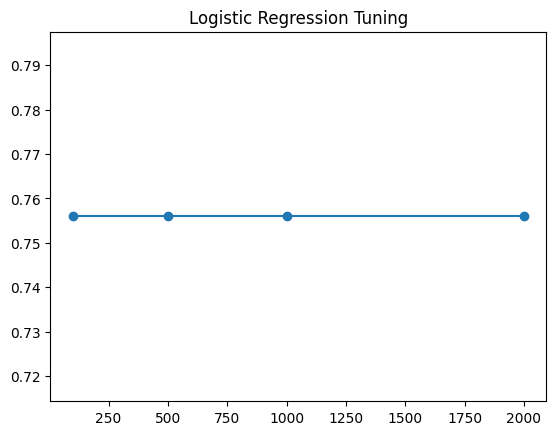

0.632768361581921


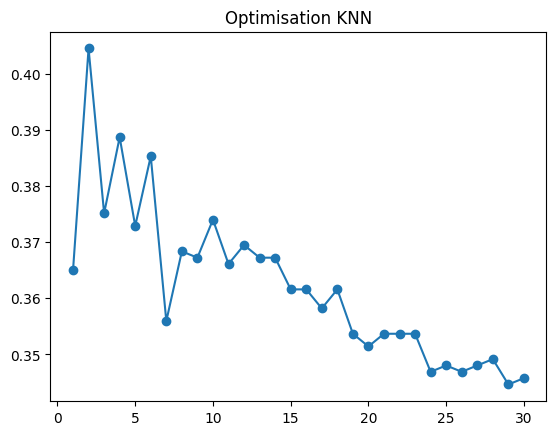

0.6836158192090396
                                           Feature  Importance
28             curricular units 2nd sem (approved)    0.356114
21          curricular units 1st sem (evaluations)    0.062102
26             curricular units 2nd sem (enrolled)    0.052927
15                         tuition fees up to date    0.048714
6                   previous qualification (grade)    0.044775
29                curricular units 2nd sem (grade)    0.043039
10                             father's occupation    0.035351
18                               age at enrollment    0.034030
27          curricular units 2nd sem (evaluations)    0.032449
11                                 admission grade    0.030357
23                curricular units 1st sem (grade)    0.030032
31                                  inflation rate    0.029822
3                                           course    0.028907
22             curricular units 1st sem (approved)    0.028647
8                           father's

In [1]:
# ============================================================
# IMPORTATION DES BIBLIOTHÈQUES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import joblib

from scipy.stats import kurtosis

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)

from imblearn.over_sampling import SMOTE


# ============================================================
# 1. CHARGEMENT DU DATASET
# ============================================================

df = pd.read_csv("Students_Decoded_Data.csv")

print("Dataset chargé avec succès")
print(df.head())


# ============================================================
# 2. EXPLORATION DES DONNÉES
# ============================================================

print(df.columns.tolist())
print(df.info())
print(df.describe())

# Valeurs manquantes
print(df.isnull().sum())

# Doublons
print("Nombre de doublons :", df.duplicated().sum())


# ============================================================
# 3. NORMALISATION DES NOMS DE COLONNES
# ============================================================

df.columns = df.columns.str.strip().str.lower()


# ============================================================
# 4. SUPPRESSION DES COLONNES INUTILES
# ============================================================

columns_to_drop = [
    'gdp',
    'unemployment rate',
    'nacionality',
    'international',
    "father's and mother's occupation"
]

df = df.drop(
    columns=[col for col in columns_to_drop if col in df.columns]
)

print("Colonnes restantes :")
print(df.columns)


# ============================================================
# 5. NETTOYAGE DES DONNÉES
# ============================================================

# Suppression des doublons
df = df.drop_duplicates()

# Remplacement des valeurs manquantes numériques
df = df.fillna(df.mean(numeric_only=True))


# ============================================================
# 6. ANALYSE DES OUTLIERS
# ============================================================

numeric_columns = df.select_dtypes(include=np.number).columns

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[numeric_columns] < (Q1 - 1.5 * IQR))
    |
    (df[numeric_columns] > (Q3 + 1.5 * IQR))
)

print(outliers.sum())


# ============================================================
# 7. VISUALISATION DES OUTLIERS (BOXPLOTS)
# ============================================================

num_vars = len(numeric_columns)
cols = 2
rows = math.ceil(num_vars / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    df[col].plot(kind='box', ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# 8. TRAITEMENT DES OUTLIERS PAR CLIPPING
# ============================================================

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

for col in numeric_columns:
    df[col] = df[col].clip(
        lower=lower_limit[col],
        upper=upper_limit[col]
    )

print(df.head())


# ============================================================
# 9. DISTRIBUTION DES VARIABLES NUMÉRIQUES
# ============================================================

num_rows = math.ceil(len(numeric_columns) / 2)

fig, axes = plt.subplots(
    nrows=num_rows,
    ncols=2,
    figsize=(12, num_rows * 3)
)

axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    df[col].plot(
        kind='hist',
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )
    axes[i].set_title(f'Distribution de {col}')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# 10. ANALYSE DES VARIABLES CATÉGORIELLES
# ============================================================

categorical_col = df.select_dtypes(include='object').columns

for col in categorical_col:
    print(f"{col}")
    print(df[col].value_counts())


# ============================================================
# 11. MATRICE DE CORRÉLATION
# ============================================================

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


# ============================================================
# 12. ANALYSE DE SKEWNESS ET KURTOSIS
# ============================================================

skew_values = df[numeric_columns].skew()
kurt_values = df[numeric_columns].kurt()

skew_kurt = pd.DataFrame({
    "Skewness": skew_values,
    "Kurtosis": kurt_values
})

print(skew_kurt)


# ============================================================
# 13. VISUALISATION DE LA KURTOSIS
# ============================================================

fig, axes = plt.subplots(10, 2, figsize=(10,15))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    kurt = df[col].kurt().round(2)

    sns.histplot(df[col], ax=axes[i], kde=True)

    axes[i].set_title(
        f"{col} | Kurtosis : {kurt}"
    )

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()


# ============================================================
# 14. VISUALISATION DU SKEWNESS
# ============================================================

plt.figure(figsize=(12,5))
sns.barplot(
    x=skew_values.index,
    y=skew_values.values
)

plt.xticks(rotation=90)
plt.axhline(0, linestyle='--')
plt.title("Skewness of Numeric Features")
plt.show()


# ============================================================
# 15. VISUALISATION DE LA KURTOSIS
# ============================================================

plt.figure(figsize=(12,5))
sns.barplot(
    x=kurt_values.index,
    y=kurt_values.values
)

plt.xticks(rotation=90)
plt.axhline(3, linestyle='--')
plt.title("Kurtosis of Numeric Features")
plt.show()


# ============================================================
# 16. ENCODAGE DES VARIABLES CATÉGORIELLES
# ============================================================

label_encoders = {}

for col in df.select_dtypes(include='object').columns:

    le = LabelEncoder()

    df[col] = le.fit_transform(df[col])

    label_encoders[col] = le


# ============================================================
# 17. DÉFINITION DE LA VARIABLE CIBLE
# ============================================================

target_column = df.columns[-1]

print("Target :", target_column)

X = df.drop(target_column, axis=1)
y = df[target_column]


# ============================================================
# 18. DIVISION TRAIN / TEST
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)


# ============================================================
# 19. NORMALISATION
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalisation terminée")


# ============================================================
# 20. ÉQUILIBRAGE DES CLASSES AVEC SMOTE
# ============================================================

smote = SMOTE(random_state=42)

X_train_res, y_train_res = smote.fit_resample(
    X_train,
    y_train
)

print(y_train_res.value_counts())


# ============================================================
# 21. MODÈLE 1 : RÉGRESSION LOGISTIQUE
# ============================================================

log_reg = LogisticRegression(
    max_iter=2000,
    class_weight='balanced'
)

log_reg.fit(X_train_res, y_train_res)

y_pred_lr = log_reg.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr,
      average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_lr,
      average='weighted'))

print(confusion_matrix(y_test, y_pred_lr))


# ============================================================
# 22. TUNING DE LA RÉGRESSION LOGISTIQUE
# ============================================================

iters = [100, 500, 1000, 2000]
scores = []

for i in iters:

    model = LogisticRegression(max_iter=i)

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    scores.append(acc)

    print(i, acc)

plt.plot(iters, scores, marker='o')
plt.title("Logistic Regression Tuning")
plt.show()


# ============================================================
# 23. MODÈLE 2 : KNN
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=13
)

knn_model.fit(X_train_res, y_train_res)

y_pred_knn = knn_model.predict(X_test)

print(accuracy_score(y_test, y_pred_knn))


# ============================================================
# 24. OPTIMISATION DE K
# ============================================================

k_values = range(1,31)

errors = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(X_train_res, y_train_res)

    pred = knn.predict(X_test)

    errors.append(
        1 - accuracy_score(y_test, pred)
    )

plt.plot(k_values, errors, marker='o')
plt.title("Optimisation KNN")
plt.show()


# ============================================================
# 25. MODÈLE 3 : DECISION TREE
# ============================================================

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(
    X_train_res,
    y_train_res
)

y_pred_dt = dt_model.predict(X_test)

print(
    accuracy_score(
        y_test,
        y_pred_dt
    )
)


# ============================================================
# 26. IMPORTANCE DES VARIABLES
# ============================================================

importances = dt_model.feature_importances_

feature_names = X.columns

df_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by='Importance',
    ascending=False
)

print(df_importance)


# ============================================================
# 27. OPTIMISATION DE L'ARBRE DE DÉCISION
# ============================================================

param_grid = {

    "max_depth":[3,5,7,10],

    "min_samples_split":[2,5,10],

    "min_samples_leaf":[1,2,5],

    "criterion":[
        "gini",
        "entropy"
    ]
}

dt_tuned_model = GridSearchCV(

    DecisionTreeClassifier(
        random_state=42
    ),

    param_grid,

    cv=5,

    scoring='accuracy'
)

dt_tuned_model.fit(
    X_train_res,
    y_train_res
)

print(
    dt_tuned_model.best_params_
)


# ============================================================
# 28. MEILLEUR ARBRE
# ============================================================

best_dt = DecisionTreeClassifier(
    **dt_tuned_model.best_params_,
    random_state=42
)

best_dt.fit(
    X_train_res,
    y_train_res
)

y_pred_best_dt = best_dt.predict(X_test)


# ============================================================
# 29. COMPARAISON DES MODÈLES
# ============================================================

results = {

    "Logistic Regression":
        accuracy_score(
            y_test,
            y_pred_lr
        ),

    "KNN":
        accuracy_score(
            y_test,
            y_pred_knn
        ),

    "Decision Tree":
        accuracy_score(
            y_test,
            y_pred_dt
        ),

    "Decision Tree Tuned":
        accuracy_score(
            y_test,
            y_pred_best_dt
        )
}

for model, score in results.items():
    print(model, score)


# ============================================================
# 30. PRÉDICTION D'UN NOUVEL ÉTUDIANT
# ============================================================

new_student = X_test[0:1]

prediction = log_reg.predict(
    new_student
)[0]

probabilities = log_reg.predict_proba(
    new_student
)

confidence = max(
    probabilities[0]
) * 100

print(prediction)
print(confidence)


# ============================================================
# 31. SAUVEGARDE DU MODÈLE FINAL
# ============================================================

joblib.dump(
    log_reg,
    "modele_reussite_academique.pkl"
)

print(
    "Modèle sauvegardé avec succès"
)
